# Wumpus World, solution 1: a hard-coded policy

**The task.** An agent in a 4×4 cave must grab the gold and climb out from (1,1).

| Event | Reward |
|---|---|
| climb out with the gold | +1000 |
| die (pit or Wumpus) | −1000 |
| every action | −1 |
| shoot the arrow | −10 |

**The idea of this solution.** A **policy** says which action to take in each state: π(s) = a. The policy is a list of **rules** `condition → action` and the agent simply looks them up at every step. All the knowledge about the cave is in the rules. The agent does not learn anything.

In [1]:
from dataclasses import dataclass
import matplotlib.pyplot as plt

## The environment

The cave: Wumpus at (1,3), gold at (2,3), pits at (3,1), (3,3) and (4,4). Squares are `(x, y)` with (1,1) at the bottom left; the agent starts there facing east.
`step(action)` executes one action and returns the **sensor messages** (`breeze`, `stench`, `glitter`, `bump`, `scream`, `at_start`) and the reward. It never tells the agent where it is.

In [ ]:
DIRS = ["east", "north", "west", "south"]          # turn_l = next one, turn_r = previous one
STEP = {"east": (1, 0), "north": (0, 1), "west": (-1, 0), "south": (0, -1)}
ACTIONS = ["fwd", "turn_l", "turn_r", "grab", "shoot", "climb"]


class Cave:
    def __init__(self, wumpus=(1, 3), gold=(2, 3), pits=((3, 1), (3, 3), (4, 4)), size=4):
        self.size, self.wumpus0, self.gold0, self.pits = size, wumpus, gold, set(pits)
        self.reset()

    def reset(self):
        self.pos, self.facing = (1, 1), "east"
        self.wumpus, self.gold = self.wumpus0, self.gold0
        self.has_gold, self.arrow, self.done = False, True, False
        self.bump = self.scream = False
        return self.sensors()

    def neighbours(self, square):
        x, y = square
        return {(x + dx, y + dy) for dx, dy in STEP.values()
                if 1 <= x + dx <= self.size and 1 <= y + dy <= self.size}

    def sensors(self):
        s = set()
        if self.wumpus and self.wumpus in self.neighbours(self.pos) | {self.pos}: s.add("stench")
        if self.pits & self.neighbours(self.pos): s.add("breeze")
        if self.gold == self.pos: s.add("glitter")
        if self.bump: s.add("bump")
        if self.scream: s.add("scream")
        if self.pos == (1, 1): s.add("at_start")
        return s

    def step(self, action):
        self.bump = self.scream = False
        reward = -1                                         # every action costs 1
        if action == "fwd":
            dx, dy = STEP[self.facing]
            new = (self.pos[0] + dx, self.pos[1] + dy)
            if 1 <= new[0] <= self.size and 1 <= new[1] <= self.size:
                self.pos = new
                if new in self.pits or new == self.wumpus:
                    self.done, reward = True, -1000         # pit or Wumpus
            else:
                self.bump = True                            # wall
        elif action == "turn_l":
            self.facing = DIRS[(DIRS.index(self.facing) + 1) % 4]
        elif action == "turn_r":
            self.facing = DIRS[(DIRS.index(self.facing) - 1) % 4]
        elif action == "grab" and self.gold == self.pos:
            self.has_gold, self.gold = True, None
        elif action == "shoot" and self.arrow:
            self.arrow, reward = False, -10
            x, y = self.pos
            dx, dy = STEP[self.facing]
            while 1 <= x <= self.size and 1 <= y <= self.size:
                if (x, y) == self.wumpus:
                    self.wumpus, self.scream = None, True
                    break
                x, y = x + dx, y + dy
        elif action == "climb" and self.pos == (1, 1):
            self.done = True
            if self.has_gold:
                reward = 1000 - 1                           # +1000, minus the action's cost
        return self.sensors(), reward

## The agent's state: observation + memory

The **environment state** is the true world while the **agent state** is the agent's own summary of its history.
Here the observation is **partial**: the sensors don't say where the agent is. On the way to the gold and on the way back it walks through the same squares, receives the same sensors, and must do different things. Deciding on sensors alone is not enough.

The agent cannot *perceive* its position, but it knows which actions it took, so it can **keep track of it**. This memory adds internal messages:
- `x1`…`x4`, `y1`…`y4`, `facing_east`… : where the agent believes it is;
- `has_gold` / `no_gold` : whether it carries the gold.

Sensors + memory form the agent state. It is **Markov**: it contains everything needed to decide, so "the future is independent of the past given the present".

In [3]:
class Memory:
    def reset(self):
        self.x, self.y, self.facing, self.has_gold = 1, 1, "east", False

    def messages(self):
        return {f"x{self.x}", f"y{self.y}", f"facing_{self.facing}",
                "has_gold" if self.has_gold else "no_gold"}

    def update(self, action, sensors_before, sensors_after):
        if action == "fwd" and "bump" not in sensors_after:
            dx, dy = STEP[self.facing]
            self.x, self.y = self.x + dx, self.y + dy
        elif action == "turn_l":
            self.facing = DIRS[(DIRS.index(self.facing) + 1) % 4]
        elif action == "turn_r":
            self.facing = DIRS[(DIRS.index(self.facing) - 1) % 4]
        elif action == "grab" and "glitter" in sensors_before:
            self.has_gold = True


def show(msgs):
    # Messages in a readable order: memory first, then sensors.
    mem = [m for m in msgs if m[0] in "xyf" or m.endswith("gold")]
    return "{" + ", ".join(sorted(mem) + sorted(set(msgs) - set(mem))) + "}"

In [4]:
def draw(cave, path, title, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(4.2, 4.2))
    for x in range(1, 5):
        for y in range(1, 5):
            ax.add_patch(plt.Rectangle((x - .5, y - .5), 1, 1, fill=False, ec="#999"))
    for (x, y) in cave.pits:
        ax.add_patch(plt.Circle((x, y), .28, color="black"))
    ax.add_patch(plt.Circle(cave.wumpus0, .28, color="#1f6b2e"))
    ax.text(*cave.wumpus0, "W", color="white", ha="center", va="center", fontweight="bold")
    gx, gy = cave.gold0
    ax.add_patch(plt.Polygon([(gx, gy + .28), (gx + .28, gy), (gx, gy - .28), (gx - .28, gy)], color="#1c5f86"))
    xs, ys = zip(*path)
    ax.plot(xs, ys, "-o", color="#b4441e", lw=3, ms=7, alpha=.85)
    ax.set_xlim(.5, 4.5); ax.set_ylim(.5, 4.5); ax.set_aspect("equal")
    ax.set_xticks(range(1, 5)); ax.set_yticks(range(1, 5)); ax.set_title(title)
    return ax

## Rules

A rule is a pair: a **condition** (a set of messages) and an **action**.

The policy is an **ordered list of rules**: at each step the agent fires **the first rule that matches**.

In [ ]:
@dataclass(frozen=True)
class Rule:
    condition: frozenset
    action: str

    def matches(self, msgs):
        return self.condition <= msgs

    def __str__(self):
        return f"{show(self.condition):<44} -> {self.action}"


def rule(condition, action):
    # rule("has_gold at_start", "climb")
    return Rule(frozenset(condition.split()), action)


class RulePolicy:
    def __init__(self, rules):
        self.rules = rules

    def __call__(self, msgs):
        for r in self.rules:
            if r.matches(msgs):
                return r
        return None

### Writing the rules

Route: (1,1) → (2,1) → (2,2) → (2,3), grab, and back the same way. Every square on it is safe.

It takes 12 actions: 4 to reach the gold, 1 to grab it, 6 to come back and 1 to climb. Every route needs at least 4 turns (one to head north, two to turn around, one to head home), at least 6 moves forward, a grab and a climb, so 12 actions is the minimum. The best possible score is therefore 1000 − 12 = **988**.

In [6]:
RULES = [
    # 1. general rules: always valid
    rule("glitter no_gold",        "grab"),     # see the gold: take it
    rule("has_gold at_start",      "climb"),    # home with the gold: leave

    # 2. outward route: (1,1) -> (2,1) -> (2,2) -> (2,3)
    rule("no_gold x1 y1 facing_east", "fwd"),    # (1,1) -> (2,1)
    rule("no_gold x2 y1 facing_east", "turn_l"), # face north
    rule("no_gold x2 facing_north",   "fwd"),    # walk up column 2

    # 3. way back: (2,3) -> (2,2) -> (2,1) -> (1,1)
    rule("has_gold x2 facing_north", "turn_r"),  # after grabbing: face east...
    rule("has_gold x2 facing_east",  "turn_r"),  # ...then south
    rule("has_gold x2 y1 facing_south", "turn_r"),  # bottom of column 2: face west (before the next rule!)
    rule("has_gold x2 facing_south", "fwd"),     # walk down column 2
    rule("has_gold x2 y1 facing_west", "fwd"),   # (2,1) -> (1,1)
]
policy = RulePolicy(RULES)

Order matters: at (2,1) facing south with the gold, both *"bottom of column 2: face west"* and *"walk down column 2"* match. The specific one comes first, otherwise the agent would walk into the wall.

## The agent

At each step the agent builds its message list (sensors + memory), asks the policy for an action, and acts. The episode ends when it climbs out, dies, or no rule matches.

In [7]:
def run_episode(policy, cave, max_steps=60, trace=True):
    memory = Memory(); memory.reset()
    sensors = cave.reset()
    score, path = 0, [cave.pos]
    for t in range(1, max_steps + 1):
        msgs = frozenset(sensors | memory.messages())
        r = policy(msgs)
        if r is None:
            if trace: print(f"{t:>2}  {show(msgs)}: no rule matches -> stop")
            break
        new_sensors, reward = cave.step(r.action)
        memory.update(r.action, sensors, new_sensors)
        sensors, score = new_sensors, score + reward
        path.append(cave.pos)
        if trace:
            print(f"{t:>2}  {show(msgs):<58} -> {r.action:<7} reward {reward:+}")
        if cave.done:
            break
    if trace: print(f"\nScore: {score}")
    return score, path

score, path = run_episode(policy, Cave())

 1  {facing_east, no_gold, x1, y1, at_start}                   -> fwd     reward -1
 2  {facing_east, no_gold, x2, y1, breeze}                     -> turn_l  reward -1
 3  {facing_north, no_gold, x2, y1, breeze}                    -> fwd     reward -1
 4  {facing_north, no_gold, x2, y2}                            -> fwd     reward -1
 5  {facing_north, no_gold, x2, y3, breeze, glitter, stench}   -> grab    reward -1
 6  {facing_north, has_gold, x2, y3, breeze, stench}           -> turn_r  reward -1
 7  {facing_east, has_gold, x2, y3, breeze, stench}            -> turn_r  reward -1
 8  {facing_south, has_gold, x2, y3, breeze, stench}           -> fwd     reward -1
 9  {facing_south, has_gold, x2, y2}                           -> fwd     reward -1
10  {facing_south, has_gold, x2, y1, breeze}                   -> turn_r  reward -1
11  {facing_west, has_gold, x2, y1, breeze}                    -> fwd     reward -1
12  {facing_west, has_gold, x1, y1, at_start}                  -> climb   re

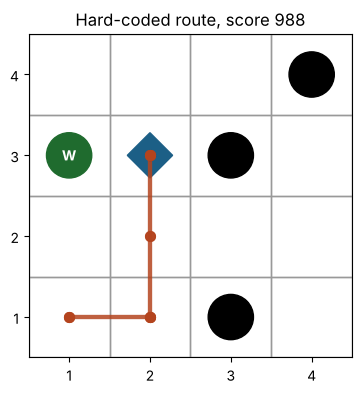

In [8]:
draw(Cave(), path, f"Hard-coded route, score {score}")
plt.show()

The agent follows the planned route and scores **988**, the best possible.

## What if the cave changes?

The rules describe **this** cave. Move the gold to (4,2) and run the same agent again.

Score in the changed cave: -60


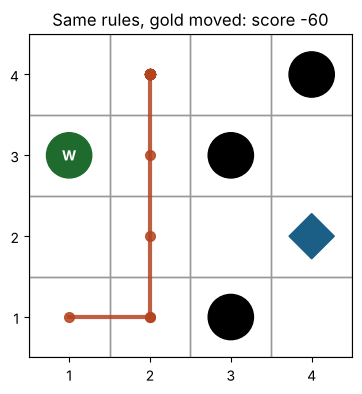

In [9]:
other = Cave(gold=(4, 2))
score2, path2 = run_episode(policy, other, trace=False)
print(f"Score in the changed cave: {score2}")
draw(other, path2, f"Same rules, gold moved: score {score2}")
plt.show()

The agent walks to (2,3) as instructed, finds no gold, keeps "walking up column 2", and bumps into the wall until the step limit: **−60**.